# Task 01 — Notebook thực hành và báo cáo mini GPT

**Người trình bày:** điền `AUTHOR` ở cell cấu hình. **Mục tiêu:** giải thích và chạy một decoder-only Transformer nhỏ từ dữ liệu văn bản đến checkpoint và sinh văn bản.

Notebook gọi lại implementation trong `mini_gpt.py`; bạn đọc và tự thực hành code theo [hướng dẫn đầy đủ](TASK_01_FULL_GUIDE.md). Các output đính kèm là lần kiểm chứng do trợ lý thực hiện. Trên máy làm báo cáo, chọn kernel của `.venv`, **Restart Kernel and Run All**, lưu notebook rồi bổ sung nhận xét của bạn.

Kết quả notebook nằm ở `out/notebook_task01/`, độc lập với các lần chạy CLI trước đó. Mỗi lần chạy lại có thể ghi đè checkpoint/log trong thư mục này; đổi `RUN_NAME` nếu muốn giữ một thực nghiệm khác.

Luồng review: **dữ liệu → tokenizer → shape/kiến trúc → causal mask → test → train 100/500 → biểu đồ → reload → báo cáo**.


## 0. Mở và chạy notebook

Từ root repo, activate `.venv` theo hệ điều hành và cài:

```bash
python -m pip install torch pytest jupyterlab matplotlib
python -m jupyterlab 02_llm_internals/TASK_01_REVIEW.ipynb
```

Có thể mở file trực tiếp bằng trình soạn thảo hỗ trợ notebook và chọn interpreter `.venv`. Dùng **Run All** từ đầu để tránh biến cũ còn trong kernel. Thiết lập CPU mặc định; không cần API key. Xem [cài đặt JupyterLab](https://jupyterlab.readthedocs.io/en/stable/getting_started/installation.html).

File `.py` chứa implementation; `.ipynb` giúp trình bày code cùng output; `.txt` là corpus; `.pt` là checkpoint. File `test_mini_gpt.py` kiểm tra code, không phải dữ liệu train chính.


In [1]:
import hashlib
import io
import json
import math
import platform
import re
import subprocess
import sys
import time
from contextlib import redirect_stdout
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "02_llm_internals/mini_gpt.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Mở notebook từ root repo hoặc bên trong 02_llm_internals/.")
MODULE_DIR = ROOT / "02_llm_internals"
if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))
from mini_gpt import CharTokenizer, Config, GPT, get_batch, train

print("Python:", sys.executable)
print("Python version:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Repo:", ROOT)


Python: /Users/quangminhnguyen/Desktop/AI Engineering/course/.venv/bin/python
Python version: 3.11.9
PyTorch: 2.14.1
Repo: /Users/quangminhnguyen/Desktop/AI Engineering/course


## 1. Cấu hình thực nghiệm

Dùng hai block, bốn head, embedding 64, context 32; mỗi head có 16 chiều. `steps` là số lần cập nhật, không phải epoch. Hai ngân sách 100/500 khởi tạo mới cùng seed, không nối tiếp checkpoint. `train()` điều chỉnh schedule theo số bước nên hai ngân sách cũng có thời lượng warmup/cosine khác nhau.

**Tự giải thích khi review:** chiều embedding khác vocabulary size như thế nào? Tại sao số chiều phải chia hết cho số head?


In [2]:
AUTHOR = "[Điền tên người thực hiện]"
RUN_NAME = "notebook_task01"
DATA_PATH = MODULE_DIR / "sample_corpus.txt"
DEVICE = "cpu"
SEED = 1337
BATCH_SIZE = 8
STEP_BUDGETS = (100, 500)
LEARNING_RATE = 0.003
LOG_EVERY = 25
ARCHITECTURE = dict(block_size=32, n_layer=2, n_head=4, n_embd=64, dropout=0.1)

assert ARCHITECTURE["n_embd"] % ARCHITECTURE["n_head"] == 0
assert min(BATCH_SIZE, LOG_EVERY, *STEP_BUDGETS) > 0
OUT_DIR = MODULE_DIR / "out" / RUN_NAME
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output:", OUT_DIR)
print("Architecture:", ARCHITECTURE)
print("Training budgets:", STEP_BUDGETS)


Output: /Users/quangminhnguyen/Desktop/AI Engineering/course/02_llm_internals/out/notebook_task01
Architecture: {'block_size': 32, 'n_layer': 2, 'n_head': 4, 'n_embd': 64, 'dropout': 0.1}
Training budgets: (100, 500)


## 2. Dữ liệu và tokenizer

`sample_corpus.txt` là văn bản thực sự đưa vào train. `CharTokenizer` dùng mỗi Unicode code point trong corpus làm một token; không dùng thư viện tokenizer pretrained. Vocabulary chứa cả dấu cách và newline. Lab `bpe.py` là thuật toán byte-pair encoding riêng, chưa nối vào mô hình này.

Vocabulary được dựng từ toàn corpus; weights chỉ cập nhật trên 90% đầu. Validation dùng 10% cuối, là một phần văn bản rất nhỏ cùng chủ đề, chưa phải test set độc lập.


In [3]:
text = DATA_PATH.read_text(encoding="utf-8")
tokenizer = CharTokenizer(text)
ids = torch.tensor(tokenizer.encode(text), dtype=torch.long)
split = int(0.9 * len(ids))
train_data, val_data = ids[:split], ids[split:]
assert min(len(train_data), len(val_data)) >= ARCHITECTURE["block_size"] + 2

sample = "hello AI"
encoded = tokenizer.encode(sample)
assert tokenizer.decode(encoded) == sample
print("Characters:", len(text))
print("Vocabulary:", len(tokenizer.chars))
print("Train / validation tokens:", len(train_data), "/", len(val_data))
print("Sample:", repr(sample))
print("Token IDs:", encoded)
print("Decoded:", tokenizer.decode(encoded))
print("Corpus preview:", repr(text[:120]))


Characters: 2004
Vocabulary: 35
Train / validation tokens: 1803 / 201
Sample: 'hello AI'
Token IDs: [17, 14, 20, 20, 23, 1, 4, 7]
Decoded: hello AI
Corpus preview: 'hello world.\nhello AI.\nAI is interesting.\nwe learn to build a small language model.\na language model predicts the next t'


## 3. Input, target và kích thước tensor

Với chuỗi `hello `: input `hello`, target `ello `. Mỗi vị trí học dự đoán token kế tiếp. Bảng shape dưới được tính từ các layer thật trong `GPT`:

`[B,T] → token + position embeddings [B,T,C] → N block → logits [B,T,V]`.

Mỗi block chứa **LayerNorm → masked attention → residual → LayerNorm → FFN/GELU → residual**. Position embedding là bảng học được; không phải sinusoidal hoặc RoPE. Cross-entropy nhận logits trực tiếp.


In [4]:
config = Config(vocab_size=len(tokenizer.chars), **ARCHITECTURE)
torch.manual_seed(SEED)
probe = GPT(config).to(DEVICE).eval()
x, y = get_batch(train_data, config.block_size, BATCH_SIZE, DEVICE)
with torch.no_grad():
    token_vectors = probe.tok_emb(x)
    positions = probe.pos_emb(torch.arange(x.shape[1], device=x.device))
    hidden = token_vectors + positions
    attention = probe.blocks[0].attn
    q, k, v = attention.qkv(probe.blocks[0].ln1(hidden)).split(config.n_embd, dim=2)
    q = q.view(BATCH_SIZE, config.block_size, config.n_head, config.n_embd // config.n_head).transpose(1, 2)
    logits, initial_loss = probe(x, y)
parameters = sum(p.numel() for p in probe.parameters())
shape_rows = [
    ("Token IDs", tuple(x.shape)),
    ("Token embeddings", tuple(token_vectors.shape)),
    ("Position embeddings (broadcast qua batch)", tuple(positions.shape)),
    ("Q sau khi chia head; K/V cùng shape", tuple(q.shape)),
    ("Logits", tuple(logits.shape)),
]
display(Markdown("| Thành phần | Shape |\n|---|---|\n" + "\n".join(f"| {name} | `{shape}` |" for name, shape in shape_rows)))
print("Input 12 ký tự:", repr(tokenizer.decode(x[0, :12].tolist())))
print("Target 12 ký tự:", repr(tokenizer.decode(y[0, :12].tolist())))
print("Unique parameters:", f"{parameters:,}")
print("Uniform loss ln(V):", round(math.log(config.vocab_size), 3))
print("Untrained batch loss:", round(initial_loss.item(), 3))


| Thành phần | Shape |
|---|---|
| Token IDs | `(8, 32)` |
| Token embeddings | `(8, 32, 64)` |
| Position embeddings (broadcast qua batch) | `(32, 64)` |
| Q sau khi chia head; K/V cùng shape | `(8, 4, 32, 16)` |
| Logits | `(8, 32, 35)` |

Input 12 ký tự: 's a token id'
Target 12 ký tự: ' a token ide'
Unique parameters: 104,384
Uniform loss ln(V): 3.555
Untrained batch loss: 3.591


## 4. Chứng minh model không nhìn token tương lai

Ở chế độ eval, thay hai token cuối trong input không được làm đổi logits ở prefix giữ nguyên. Mask tam giác dưới cho phép nhìn chính vị trí hiện tại và quá khứ. Việc che tương lai giúp tránh lộ đáp án trong next-token training.

**Câu hỏi review:** tại sao đặt score tương lai bằng `-inf` trước softmax, thay vì đặt bằng 0?


In [5]:
print("Causal mask (8 vị trí đầu):")
print(probe.blocks[0].attn.mask[0, 0, :8, :8].int().cpu())
original = torch.tensor([tokenizer.encode("hello AI")], dtype=torch.long, device=DEVICE)
changed = original.clone()
changed[:, -2:] = (changed[:, -2:] + 1) % config.vocab_size
with torch.no_grad():
    before, _ = probe(original)
    after, _ = probe(changed)
max_prefix_difference = (before[:, :-2] - after[:, :-2]).abs().max().item()
assert max_prefix_difference < 1e-6
print("Max difference ở prefix:", max_prefix_difference)
print("Causal behavior: PASS")


Causal mask (8 vị trí đầu):
tensor([[1, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1]], dtype=torch.int32)
Max difference ở prefix: 0.0
Causal behavior: PASS


## 5. Kiểm thử implementation

Chạy `test_mini_gpt.py` bằng đúng interpreter của kernel. Các test kiểm tra tokenizer, shift target, causal behavior, gradient và CLI/checkpoint. `8 passed` của phiên bản gốc là bằng chứng kỹ thuật; không phải thước đo khả năng ngôn ngữ.


In [6]:
test_result = subprocess.run(
    [sys.executable, "-m", "pytest", str(MODULE_DIR / "test_mini_gpt.py"), "-q"],
    cwd=ROOT, capture_output=True, text=True,
)
test_output = test_result.stdout + test_result.stderr
(OUT_DIR / "tests.log").write_text(test_output, encoding="utf-8")
print(test_output)
assert test_result.returncode == 0, "Sửa test lỗi trước khi train chính."


........                                                                 [100%]
8 passed in 2.01s



## 6. Huấn luyện hai ngân sách

Hàm bên dưới chỉ thu thập output quanh `train()` hiện có; thuật toán huấn luyện vẫn nằm trong `mini_gpt.py`. Mỗi lần gọi tạo GPT mới cùng seed, lưu checkpoint và log riêng.

`train()` thực hiện forward → cross-entropy → backward → clip gradient → AdamW.step → scheduler.step. Validation lấy trung bình 20 batch ngẫu nhiên và không cập nhật weights. Đo thời gian ở đây gồm train và đánh giá trong vòng train, không gồm cài package/import hoặc sinh mẫu.

Tăng số bước không tăng số tham số. Khi thay đổi cấu hình, đổi `RUN_NAME` và chạy lại toàn notebook.


In [7]:
def run_experiment(steps):
    torch.manual_seed(SEED)
    model = GPT(Config(vocab_size=len(tokenizer.chars), **ARCHITECTURE)).to(DEVICE)
    captured = io.StringIO()
    started = time.perf_counter()
    with redirect_stdout(captured):
        train(model, train_data, val_data, steps, LEARNING_RATE, BATCH_SIZE, DEVICE, log_every=LOG_EVERY)
    train_seconds = time.perf_counter() - started
    log = captured.getvalue()
    (OUT_DIR / f"train_{steps}.log").write_text(log, encoding="utf-8")
    history = [dict(step=int(s), train=float(t), validation=float(v))
               for s, t, v in re.findall(r"step\s+(\d+) \| train ([0-9.]+) \| val ([0-9.]+)", log)]
    assert history and history[-1]["step"] == steps
    checkpoint = OUT_DIR / f"model_{steps}.pt"
    torch.save({"model": model.state_dict(), "config": model.config.__dict__, "chars": tokenizer.chars}, checkpoint)
    print(f"=== {steps} steps | {sum(p.numel() for p in model.parameters()):,} parameters ===")
    print(log)
    return dict(steps=steps, history=history, train_seconds=train_seconds,
                parameters=sum(p.numel() for p in model.parameters()),
                checkpoint=checkpoint.name, config=model.config.__dict__)

runs = [run_experiment(steps) for steps in STEP_BUDGETS]


=== 100 steps | 104,384 parameters ===
step     0 | train 3.593 | val 3.591 | lr 6.0e-04 | 0s
step    25 | train 2.644 | val 2.650 | lr 2.6e-03 | 0s
step    50 | train 2.442 | val 2.436 | lr 1.7e-03 | 0s
step    75 | train 2.332 | val 2.379 | lr 7.0e-04 | 1s
step   100 | train 2.306 | val 2.347 | lr 3.0e-04 | 1s



=== 500 steps | 104,384 parameters ===
step     0 | train 3.593 | val 3.591 | lr 1.2e-04 | 0s
step    25 | train 2.755 | val 2.773 | lr 3.0e-03 | 0s
step    50 | train 2.436 | val 2.432 | lr 2.9e-03 | 0s
step    75 | train 2.315 | val 2.404 | lr 2.9e-03 | 1s
step   100 | train 2.283 | val 2.318 | lr 2.7e-03 | 1s
step   125 | train 2.257 | val 2.369 | lr 2.6e-03 | 1s
step   150 | train 2.165 | val 2.348 | lr 2.4e-03 | 1s
step   175 | train 2.055 | val 2.337 | lr 2.3e-03 | 1s
step   200 | train 2.049 | val 2.343 | lr 2.1e-03 | 2s
step   225 | train 1.990 | val 2.383 | lr 1.9e-03 | 2s
step   250 | train 1.926 | val 2.380 | lr 1.7e-03 | 2s
step   275 | train 1.885 | val 2.423 | lr 1.4e-03 | 2s
step   300 | train 1.827 | val 2.374 | lr 1.2e-03 | 2s
step   325 | train 1.763 | val 2.366 | lr 1.0e-03 | 3s
step   350 | train 1.695 | val 2.411 | lr 8.6e-04 | 3s
step   375 | train 1.650 | val 2.392 | lr 7.0e-04 | 3s
step   400 | train 1.614 | val 2.415 | lr 5.6e-04 | 3s
step   425 | train 1.603 |

## 7. Biểu đồ loss và bảng kết quả

Quan sát đồng thời train và validation. Train tiếp tục giảm nhưng val chững/tăng là dấu hiệu phù hợp overfitting trên corpus này. Một seed, val nhỏ và các cửa sổ có thể chồng lấn chưa đủ kết luận chất lượng tổng quát. So sánh ngân sách 100/500 cũng bao gồm thay đổi thời lượng schedule.

Biểu đồ được xuất thành `loss_curves.png` để chèn vào báo cáo hoặc trình chiếu.


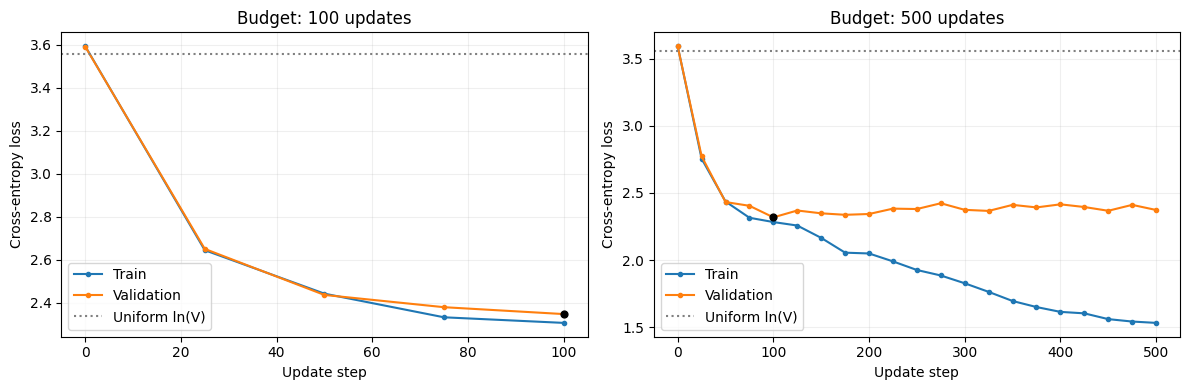

| Updates | Parameters | Train đầu/cuối | Val đầu/cuối | Val tốt nhất trong log | Giây train + eval |
|---|---:|---|---|---|---:|
| 100 | 104,384 | 3.593 → 2.306 | 3.591 → 2.347 | 2.347 @ 100 | 1.48 |
| 500 | 104,384 | 3.593 → 1.532 | 3.591 → 2.373 | 2.318 @ 100 | 3.93 |

In [8]:
fig, axes = plt.subplots(1, len(runs), figsize=(6 * len(runs), 4), squeeze=False)
for ax, run in zip(axes[0], runs):
    history = run["history"]
    ax.plot([h["step"] for h in history], [h["train"] for h in history], label="Train", marker=".")
    ax.plot([h["step"] for h in history], [h["validation"] for h in history], label="Validation", marker=".")
    ax.axhline(math.log(config.vocab_size), color="gray", linestyle=":", label="Uniform ln(V)")
    best = min(history, key=lambda h: h["validation"])
    ax.scatter([best["step"]], [best["validation"]], color="black", s=24, zorder=3)
    ax.set(title=f"Budget: {run['steps']} updates", xlabel="Update step", ylabel="Cross-entropy loss")
    ax.grid(alpha=0.2)
    ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

rows = []
for run in runs:
    first, last = run["history"][0], run["history"][-1]
    best = min(run["history"], key=lambda h: h["validation"])
    rows.append(f"| {run['steps']} | {run['parameters']:,} | {first['train']:.3f} → {last['train']:.3f} | {first['validation']:.3f} → {last['validation']:.3f} | {best['validation']:.3f} @ {best['step']} | {run['train_seconds']:.2f} |")
summary_table = "| Updates | Parameters | Train đầu/cuối | Val đầu/cuối | Val tốt nhất trong log | Giây train + eval |\n|---|---:|---|---|---|---:|\n" + "\n".join(rows)
display(Markdown(summary_table))


## 8. Nạp checkpoint và sinh từ prompt

Nạp lại weights từ đĩa để chứng minh artifact dùng được độc lập với đối tượng model lúc train. Dùng `config` và `chars` cùng checkpoint, gọi `eval()` tắt dropout; `generate()` đã có `no_grad()`.

Sampling seed 42, prompt và temperature được giữ giống nhau giữa hai checkpoint. Văn bản sinh có thể lộn xộn; ghi nhận đúng kết quả, không suy ra model đã thành chatbot.


In [9]:
prompt = "hello "
for run in runs:
    saved = torch.load(OUT_DIR / run["checkpoint"], map_location="cpu", weights_only=True)
    restored = GPT(Config(**saved["config"])).eval()
    restored.load_state_dict(saved["model"])
    chars = saved["chars"]
    stoi = {char: i for i, char in enumerate(chars)}
    missing = sorted(set(prompt) - set(chars))
    assert not missing, f"Prompt có ký tự ngoài vocabulary: {missing}"
    inputs = torch.tensor([[stoi[char] for char in prompt]], dtype=torch.long)
    with torch.no_grad():
        check_logits, _ = restored(inputs)
    assert torch.isfinite(check_logits).all()
    torch.manual_seed(42)
    generated = restored.generate(inputs, max_new_tokens=120, temperature=0.8)
    sample_text = "".join(chars[i] for i in generated[0].tolist())
    run["sample"] = sample_text
    run["reload"] = "passed"
    (OUT_DIR / f"generate_{run['steps']}.log").write_text(sample_text, encoding="utf-8")
    print(f"=== Reload {run['checkpoint']} | prompt={prompt!r} ===")
    print(sample_text, "\n")


=== Reload model_100.pt | prompt='hello ' ===
hello ppipas e feuut benct pace tis ge in o e in tited denk as tinthe  tun de mxthens ct.
ro uaned urrinden tis warens tisch o 

=== Reload model_500.pt | prompt='hello ' ===
hello putput enge ut odel mppde the weights cores iter o bemald the ua tendd preditss atenoo utens uredad pat tookes pdaten th 



## 9. Lưu metadata và bản báo cáo thực nghiệm

Cell này ghi số liệu thực tế, phiên bản, hash source/corpus và hình loss. Báo cáo có chỗ để bạn bổ sung tên, phần tự code và phân tích. Nếu đã có `REPORT.md`, bản sinh lại được ghi vào `REPORT_generated.md` để giữ nội dung bạn đã biên tập.

Metadata/hash được đo trong lần chạy notebook này. Restart và Run All sau khi thay source để output phản ánh đúng implementation.


In [10]:
def git_value(*args):
    try:
        return subprocess.check_output(["git", *args], cwd=ROOT, text=True, stderr=subprocess.DEVNULL).strip()
    except (FileNotFoundError, subprocess.CalledProcessError):
        return None

metadata = dict(
    author=AUTHOR, recorded_at=datetime.now().astimezone().isoformat(),
    python=platform.python_version(), torch=torch.__version__, platform=platform.platform(),
    device=DEVICE, cpu_threads=torch.get_num_threads(), git_commit=git_value("rev-parse", "HEAD"),
    git_status=git_value("status", "--short"), dataset=str(DATA_PATH.relative_to(ROOT)),
    dataset_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    characters=len(text), vocabulary=len(tokenizer.chars), train_tokens=len(train_data), val_tokens=len(val_data),
    seed=SEED, batch_size=BATCH_SIZE, lr=LEARNING_RATE, log_every=LOG_EVERY,
    generation=dict(prompt=prompt, seed=42, temperature=0.8, new_tokens=120),
    tests_exit_code=test_result.returncode,
    source_sha256={name: hashlib.sha256((MODULE_DIR / name).read_bytes()).hexdigest()
                   for name in ("mini_gpt.py", "bpe.py", "test_mini_gpt.py")},
    runs=runs,
)
(OUT_DIR / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
report_lines = [
    "# Báo cáo Task 01 — Mini GPT decoder-only", "",
    f"Người thực hiện: {AUTHOR}. Thời gian: {metadata['recorded_at']}.", "",
    "## 1. Mục tiêu và phần tự triển khai", "",
    "[Điền phần bạn tự viết/sửa; nêu rõ phần dựa trên implementation của lab.]", "",
    "## 2. Kiến trúc và dữ liệu", "",
    f"Corpus {len(text)} ký tự; vocabulary {config.vocab_size}; split {len(train_data)}/{len(val_data)} token.", "",
    f"Config: `{ARCHITECTURE}`; batch {BATCH_SIZE}; lr cơ sở {LEARNING_RATE}; seed {SEED}; device {DEVICE}.", "",
    "[Giải thích tokenizer, embedding/vị trí, masked attention, FFN, residual và logits.]", "",
    "## 3. Kết quả đo", "", summary_table, "",
    "![Loss curves](loss_curves.png)", "",
    "Hai ngân sách khởi tạo mới, schedule phụ thuộc steps. Thời gian chỉ gồm train và đánh giá trong vòng train.", "",
]
for run in runs:
    report_lines += [f"### Mẫu sinh sau {run['steps']} updates", "", "```text", run["sample"], "```", ""]
report_lines += [
    "## 4. Kiểm thử và bằng chứng", "",
    "[Test log](tests.log), [metadata](metadata.json), checkpoint và log train/generate nằm cùng thư mục.", "",
    "Các checkpoint reload thành công và forward hữu hạn. Test kỹ thuật không đo chất lượng ngôn ngữ.", "",
    "## 5. Phân tích và hạn chế", "",
    "[So sánh train/val và nhận xét mẫu sinh. Giải thích dấu hiệu overfitting, corpus/val nhỏ, context và tokenizer ký tự.]", "",
    "## 6. Tái hiện", "",
    "Mở `../../TASK_01_REVIEW.ipynb`, chọn kernel .venv, Restart Kernel and Run All rồi lưu notebook.", "",
]
report_path = OUT_DIR / "REPORT.md"
if report_path.exists():
    report_path = OUT_DIR / "REPORT_generated.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print("Report:", report_path)
print("Metadata:", OUT_DIR / "metadata.json")
print("Chart:", OUT_DIR / "loss_curves.png")


Report: /Users/quangminhnguyen/Desktop/AI Engineering/course/02_llm_internals/out/notebook_task01/REPORT.md
Metadata: /Users/quangminhnguyen/Desktop/AI Engineering/course/02_llm_internals/out/notebook_task01/metadata.json
Chart: /Users/quangminhnguyen/Desktop/AI Engineering/course/02_llm_internals/out/notebook_task01/loss_curves.png


## 10. Dùng notebook để báo cáo trong 5–10 phút

1. **Mục tiêu:** mô hình học dự đoán token kế tiếp, chọn decoder-only.
2. **Dữ liệu:** chỉ corpus, vocabulary và ví dụ input/target.
3. **Kiến trúc:** dùng bảng shape, giải thích attention/FFN và position embedding.
4. **Tính đúng:** mở causal mask và test output, phân biệt với đánh giá chất lượng.
5. **Kết quả:** mở biểu đồ và bảng train/val; giải thích ngân sách dài hơn có thể overfit.
6. **Demo:** nạp checkpoint, sinh văn bản; nêu giới hạn của model nhỏ.

### Nhận xét của người thực hiện — điền trước khi nộp

- Phần tôi tự cài đặt hoặc sửa dựa trên lab: **[điền]**.
- Sự khác nhau giữa train loss và validation loss trong kết quả của tôi: **[điền]**.
- Mẫu sinh cho thấy điều gì, còn hạn chế gì: **[điền]**.
- Một cải tiến tiếp theo và cách kiểm tra: **[điền]**.

### Bài nộp

Lưu notebook sau Run All để giữ output và hình. Đính kèm `REPORT.md`, `metadata.json`, `loss_curves.png`, log và checkpoint của `out/notebook_task01/`. Source `.py` cần đi cùng để reviewer tái hiện. Thư mục `out/` bị Git bỏ qua; notebook `.ipynb` có thể commit, còn artifacts đính kèm qua gói nộp. Hướng dẫn chức năng chi tiết ở [TASK_01_FULL_GUIDE.md](TASK_01_FULL_GUIDE.md).

**Chú ý về trạng thái:** chạy mỗi cell theo thứ tự; nếu sửa source hoặc cấu hình, Restart Kernel and Run All. Nội dung tự sinh là bản nháp kỹ thuật, cần bổ sung phần hiểu và phân tích của bạn.
